# Bank Account Fraud (BAF) - Model Training and Hyperparameter Tuning

Steps covered in this notebook:

1. **Load data** - reads the preprocessed train/validation sets written by `02_preprocessing_and_baselines` from `../data/preprocessed/{lr,xgb}/`
2. **Evaluation setup** - metrics at a fixed 5% FPR threshold (the BAF benchmark convention), plus predictive equality across age groups as a fairness check
3. **Baseline models** - logistic regression and XGBoost with near-default settings, compared on ROC AUC, PR AUC and recall at 5% FPR
4. **MLflow tracking** - log each baseline with its parameters, metrics, plots, classification report and model artifact
5. **Hyperparameter tuning** - Optuna random search for each model, maximising recall at 5% FPR on the validation month. Each trial logged through a nested MLFlow run
6. **Save models** - write the baseline and tuned models to `../models/` for `04_evaluation_and_fairness` (baseline vs tuned comparison and fairness) and `05_explainability`

With `LOG_TO_MLFLOW = True`, requires a local MLFlow server running at 'http://localhost:5000' and a GPU for XGB training (set `XGB_DEVICE = 'cpu'` otherwise).

Shared helpers are imported from the `baf` package in `../src/baf/` (install once with `pip install -e .` from the project root).

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import pandas as pd
import numpy as np

import joblib
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

import mlflow
import optuna

from baf.config import MODELS_DIR, TARGET_FPR, TRAIN_MONTHS, VAL_MONTHS
from baf.data import load_split
from baf.metrics import evaluate_model
from baf.plotting import HIGHLIGHT_COLOR, REFERENCE_COLOR, TEXT_COLOR, style_axis
from baf.tracking import (METRIC_NAMES, log_model_run, setup_mlflow, start_run, to_mlflow_metrics,
                          xgb_serving_model)

In [2]:
# Controls MLFlow logging
LOG_TO_MLFLOW = False

## Load Data

Both feature sets come from `02_preprocessing_and_baselines`. The LR features are already scaled, imputed and one-hot encoded; the XGBoost features keep `NaN`s and `category` columns. Both share the same rows and targets.

In [3]:
X_train_lr, X_val_lr, y_train, y_val = load_split("lr")
X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = load_split("xgb")

# Both feature sets must line up row for row with the same targets
assert X_train_lr.index.equals(X_train_xgb.index) and X_val_lr.index.equals(X_val_xgb.index)
assert y_train.equals(y_train_xgb) and y_val.equals(y_val_xgb)
assert X_train_lr.index.equals(y_train.index) and X_val_lr.index.equals(y_val.index)

y_val_array = y_val.to_numpy()
# Unscaled ages for the fairness metrics (the LR copy of customer_age is standardised)
val_age = X_val_xgb["customer_age"].to_numpy()

print(f"LR:  train {X_train_lr.shape}, val {X_val_lr.shape}")
print(f"XGB: train {X_train_xgb.shape}, val {X_val_xgb.shape}")
print(f"Fraud rate: train {y_train.mean():.2%}, val {y_val.mean():.2%}")

LR:  train (903157, 50), val (96843, 50)
XGB: train (903157, 33), val (96843, 33)
Fraud rate: train 1.06%, val 1.47%


## Evaluation

- **ROC AUC / PR AUC** are threshold-free. PR AUC (average precision) is the more informative of the two here (Random classifier threshold is class ratio 0.01 instead of 0.5)
- **Precision, Recall, TPR, FPR** need a decision threshold. Following the BAF benchmark convention, the threshold is set so the overall FPR on the validation month is 5%, which puts every model at the same operating point. Recall and TPR are the same quantity.
- **Predictive equality** compares FPR between age groups (`customer_age` < 50 vs >= 50, as in the BAF paper), reported as the lower FPR divided by the higher. 1.0 means both groups are wrongly flagged at the same rate.
- **Predictive equality (all ages)** applies the same idea across every decade bucket of `customer_age`: the lowest bucket FPR divided by the highest. The 90s bucket has only 3 validation rows, so it is merged into 80+.

The threshold is picked on the validation month itself, so the threshold metrics are slightly optimistic; a held-out test month is needed for an unbiased estimate.

The metrics are computed by `evaluate_model` in `src/baf/metrics.py`.

## Baseline Models

Both models are trained on months 0-6 and evaluated on the validation month (7), with class imbalance handled by reweighting: `class_weight='balanced'` for logistic regression and `scale_pos_weight` (non-fraud / fraud count) for XGBoost.

In [4]:
lr_model = LogisticRegression(class_weight="balanced", max_iter=1000)
lr_model.fit(X_train_lr, y_train)

lr_val_scores = lr_model.predict_proba(X_val_lr)[:, 1]

In [5]:
# Non-fraud to fraud ratio in the training months
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train_xgb, y_train)

xgb_val_scores = xgb_model.predict_proba(X_val_xgb)[:, 1]

scale_pos_weight: 93.1


In [6]:
val_scores = {
    "Logistic Regression": lr_val_scores,
    "XGBoost": xgb_val_scores,
}

metrics_by_model = {}
for name, scores in val_scores.items():
    metrics_by_model[name] = evaluate_model(y_val_array, scores, val_age)

# One row per model, one column per metric
results = pd.DataFrame.from_dict(metrics_by_model, orient="index")
results.round(4)

,ROC AUC,PR AUC,Threshold,Precision,Recall,TPR,FPR,FPR age < 50,FPR age >= 50,Predictive equality,Predictive equality (all ages)
Logistic Regression,0.8917,0.2052,0.7493,0.1412,0.5469,0.5469,0.0498,0.0394,0.1203,0.3279,0.0411
XGBoost,0.8763,0.1769,0.6679,0.1320,0.5077,0.5077,0.0500,0.0385,0.1275,0.3021,0.0674


## MLflow Tracking

Each baseline is logged as its own run with its parameters, validation metrics, ROC/PR and confusion-matrix plots, a classification report, the FPR in each age bucket (as metrics and a CSV), and the model with a signature and input example. Threshold metrics and the report use the same 5% FPR threshold as the results table.

Both models are logged with the `sklearn` flavor and `pyfunc_predict_fn='predict_proba'`, so a loaded pyfunc model returns fraud probabilities rather than labels at a 0.5 cutoff. The XGBoost model is logged behind a step that restores its categorical dtypes, since served JSON input arrives as strings. The logistic regression model expects the already-preprocessed `X_*_lr` columns.

Set `LOG_TO_MLFLOW = False` (top of the notebook) to re-run for results and plots without creating any MLflow runs; nothing below needs the tracking server then.

`log_model_run` is in `src/baf/tracking.py`.

In [7]:
if LOG_TO_MLFLOW:
    setup_mlflow()

In [8]:
log_model_run("Logistic Regression", lr_model, X_val_lr, y_val_array, lr_val_scores, val_age,
              log_to_mlflow=LOG_TO_MLFLOW)
log_model_run("XGBoost", xgb_model, X_val_xgb, y_val_array, xgb_val_scores, val_age,
              log_to_mlflow=LOG_TO_MLFLOW, serving_model=xgb_serving_model(xgb_model, X_train_xgb))

Logistic Regression (threshold 0.7493)
              precision    recall  f1-score   support

   Non-Fraud     0.9929    0.9502    0.9711     95415
       Fraud     0.1412    0.5469    0.2244      1428

    accuracy                         0.9442     96843
   macro avg     0.5670    0.7486    0.5977     96843
weighted avg     0.9804    0.9442    0.9601     96843

XGBoost (threshold 0.6679)
              precision    recall  f1-score   support

   Non-Fraud     0.9923    0.9500    0.9707     95415
       Fraud     0.1320    0.5077    0.2096      1428

    accuracy                         0.9435     96843
   macro avg     0.5622    0.7289    0.5901     96843
weighted avg     0.9796    0.9435    0.9595     96843



## Hyperparameter Tuning

Both models are tuned with an Optuna random search (`RandomSampler`, seeded). Each trial trains on months 0-6 and is scored on validation month 7. The objective is **recall at the 5% FPR threshold**, the BAF benchmark's headline metric.

Search spaces. Optuna can't combine `step` with `log=True`, so the log-uniform ranges are continuous. The uniform ranges are discretised; nearby values make no measurable difference, so a finer grid would only spread trials out.

| Model | Hyperparameter | Range | Distribution | Step |
|---|---|---|---|---|
| LR | `C` | 1e-4 to 1e2 | Log-uniform | continuous |
| LR | `l1_ratio` | 0 to 1 | Uniform | 0.05 |
| LR | `class_weight` | None, balanced | Categorical | - |
| XGB | `learning_rate` | 0.01 to 0.3 | Log-uniform | continuous |
| XGB | `max_depth` | 3 to 10 | Uniform integer | 1 |
| XGB | `min_child_weight` | 1 to 100 | Log-uniform | continuous |
| XGB | `subsample` | 0.5 to 1.0 | Uniform | 0.05 |
| XGB | `colsample_bytree` | 0.5 to 1.0 | Uniform | 0.05 |
| XGB | `reg_lambda` | 1e-3 to 100 | Log-uniform | continuous |
| XGB | `reg_alpha` | 1e-3 to 10 | Log-uniform | continuous |
| XGB | `gamma` | 1e-3 to 10 | Log-uniform | continuous |
| XGB | `scale_pos_weight` | 1 to 100 | Log-uniform | continuous |

- **Logistic regression** needs the `saga` solver for elastic-net. Its step size ignores sample weights, so with `class_weight='balanced'` (~46x weight on fraud rows) it diverges. The balanced case is therefore fitted with the weights rescaled to at most 1 and `C` scaled up by the same factor, which is the same objective.
- **XGBoost** isn't given a fixed `n_estimators`. A low `learning_rate` needs far more trees than a high one, so each trial grows up to 2,000 trees and early-stops on validation PR AUC after 100 rounds without improvement. Trials train on the GPU, and each model is switched to CPU before scoring and logging.

**MLflow:** each search is one parent run (`<model> random search`) with one nested run per trial. Trial runs hold the sampled parameters, every validation metric and the fit time. The parent holds the search space, the best trial's parameters, a `trials.csv` export and a search-history plot. The best model from each search is then logged as its own top-level run (`<model> (tuned)`), with the same plots, report and model artifact as the baselines, so it sits next to them in the experiment.

Both the hyperparameters and the threshold are now chosen on validation month 7, so the validation metrics of the tuned models are optimistic. The held-out test month caveat from the baselines applies even more here.

In [9]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

TUNING_METRIC = "Recall"
SEARCH_SEED = 420


def plot_search_history(study, title):
    values = np.array([trial.value for trial in study.trials])
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.scatter(np.arange(len(values)), values, s=16, color=REFERENCE_COLOR, label="Trial")
    ax.plot(np.maximum.accumulate(values), drawstyle="steps-post", color=HIGHLIGHT_COLOR, linewidth=2,
            label="Best so far")
    style_axis(ax, title, f"{TUNING_METRIC} at {TARGET_FPR:.0%} FPR")
    ax.set_xlabel("Trial", fontsize=8, color=TEXT_COLOR)
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    fig.tight_layout()
    return fig


def log_search_settings(n_trials):
    mlflow.log_params({
        "sampler": "RandomSampler",
        "sampler_seed": SEARCH_SEED,
        "n_trials": n_trials,
        "tuning_metric": METRIC_NAMES[TUNING_METRIC],
        "train_months": TRAIN_MONTHS,
        "val_months": VAL_MONTHS,
        "target_fpr": TARGET_FPR,
    })


def log_search_results(study, fig):
    # Every trial samples from the same distributions, so the first one documents the search space
    search_space = study.trials[0].distributions
    mlflow.log_params({f"space_{param}": repr(dist) for param, dist in search_space.items()})

    best_params = {"best_trial": study.best_trial.number}
    for param, value in study.best_params.items():
        best_params[f"best_{param}"] = value
    mlflow.log_params(best_params)
    mlflow.log_metric(f"best_{METRIC_NAMES[TUNING_METRIC]}", study.best_value)
    mlflow.log_text(study.trials_dataframe().to_csv(index=False), "trials.csv")
    mlflow.log_figure(fig, "search_history.png")


def run_random_search(name, suggest_params, fit_model, X_val_model, n_trials):
    # fit_model(params) returns the fitted model and a dict of extra per-trial metrics to log.
    # The best model is kept in memory so it can be logged with full artifacts without refitting.
    # best holds value, trial, params, model and scores for the best trial, plus search_run_id at the end
    best = {}

    def objective(trial):
        params = suggest_params(trial)
        with start_run(LOG_TO_MLFLOW, run_name=f"{name} trial {trial.number}", nested=True):
            start = time.perf_counter()
            model, fit_metrics = fit_model(params)
            fit_seconds = time.perf_counter() - start

            scores = model.predict_proba(X_val_model)[:, 1]
            metrics = evaluate_model(y_val_array, scores, val_age)

            trial_metrics = to_mlflow_metrics(metrics)
            trial_metrics.update(fit_metrics)
            trial_metrics["fit_seconds"] = fit_seconds

            if LOG_TO_MLFLOW:
                mlflow.log_params({**params, "decision_threshold": metrics["Threshold"]})
                mlflow.log_metrics(trial_metrics)

        value = metrics[TUNING_METRIC]
        if not best or value > best["value"]:
            best.update(value=value, trial=trial.number, params=params, model=model, scores=scores)
        return value

    study = optuna.create_study(study_name=f"{name} random search", direction="maximize",
                                sampler=optuna.samplers.RandomSampler(seed=SEARCH_SEED))

    with start_run(LOG_TO_MLFLOW, run_name=f"{name} random search") as search_run:
        if LOG_TO_MLFLOW:
            log_search_settings(n_trials)
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

        fig = plot_search_history(study, f"{name} random search on validation month 7")
        if LOG_TO_MLFLOW:
            log_search_results(study, fig)
        plt.show()

    best["search_run_id"] = search_run.info.run_id if LOG_TO_MLFLOW else None
    print(f"Best trial {best['trial']}: {TUNING_METRIC} {best['value']:.4f}")
    print(best["params"])
    return study, best


def log_tuned_run(name, best, X_val_model, params=None, serving_model=None, extra_params=None):
    run_params = {
        "tuning_metric": METRIC_NAMES[TUNING_METRIC],
        "best_trial": best["trial"],
        "search_run_id": best["search_run_id"],
    }
    if extra_params:
        run_params.update(extra_params)
    log_model_run(name, best["model"], X_val_model, y_val_array, best["scores"], val_age,
                  log_to_mlflow=LOG_TO_MLFLOW, run_name=name, params=params, serving_model=serving_model,
                  extra_params=run_params)

### Logistic Regression

  0%|          | 0/50 [00:00<?, ?it/s]

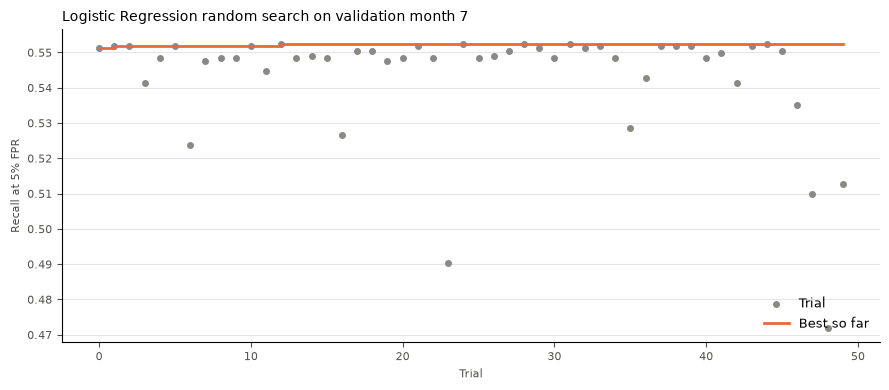

Best trial 12: Recall 0.5525
{'C': 7.836254222045934, 'l1_ratio': 0.8500000000000001, 'class_weight': None}


In [10]:
LR_N_TRIALS = 50

n_fraud = y_train.sum()
n_non_fraud = len(y_train) - n_fraud
# 'balanced' weights each class by n / (2 * class count): about 0.51 for non-fraud and 47.0 for fraud here.
# saga's step size ignores sample weights, so a weight of 47 makes it diverge. Dividing both weights by 47.0
# (giving about 0.0107 and 1.0) and multiplying C by 47.0 leaves the objective unchanged but keeps saga stable.
BALANCED_C_SCALE = len(y_train) / (2 * n_fraud)
BALANCED_SAGA_WEIGHTS = {0: float(n_fraud / n_non_fraud), 1: 1.0}


def suggest_lr_params(trial):
    return {
        "C": trial.suggest_float("C", 1e-4, 1e2, log=True),
        "l1_ratio": trial.suggest_float("l1_ratio", 0.0, 1.0, step=0.05),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }


def make_lr_model(C, l1_ratio, class_weight):
    if class_weight == "balanced":
        C = C * BALANCED_C_SCALE
        class_weight = BALANCED_SAGA_WEIGHTS
    return LogisticRegression(C=C, l1_ratio=l1_ratio, class_weight=class_weight, solver="saga",
                              max_iter=1000, random_state=42)


def fit_lr(params):
    model = make_lr_model(**params).fit(X_train_lr, y_train)
    return model, {"n_iter": model.n_iter_[0]}


lr_study, lr_best = run_random_search("Logistic Regression", suggest_lr_params, fit_lr, X_val_lr, LR_N_TRIALS)

In [11]:
lr_tuned = lr_best["model"]

# Log C and class_weight as sampled, so they read the same as the baseline and trial runs; the values saga
# was actually fitted with are kept alongside
lr_tuned_params = {
    **lr_tuned.get_params(),
    **lr_best["params"],
    "saga_C": lr_tuned.C,
    "saga_class_weight": lr_tuned.class_weight,
}
log_tuned_run("Logistic Regression (tuned)", lr_best, X_val_lr, params=lr_tuned_params)

Logistic Regression (tuned) (threshold 0.0329)
              precision    recall  f1-score   support

   Non-Fraud     0.9930    0.9500    0.9710     95415
       Fraud     0.1419    0.5525    0.2258      1428

    accuracy                         0.9441     96843
   macro avg     0.5675    0.7513    0.5984     96843
weighted avg     0.9805    0.9441    0.9600     96843



### XGBoost

  0%|          | 0/50 [00:00<?, ?it/s]

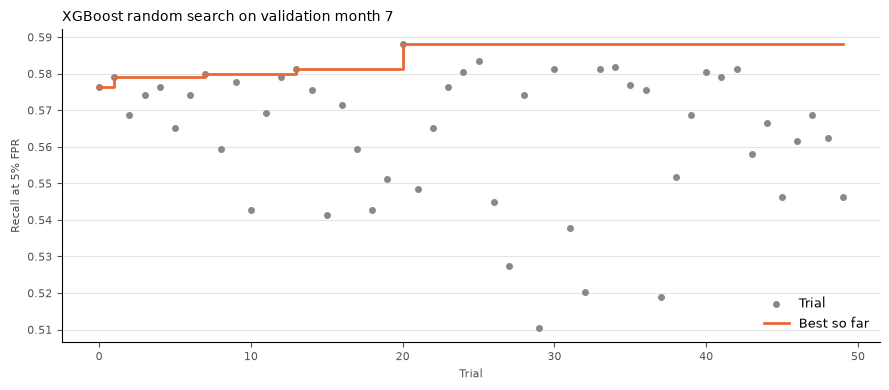

Best trial 20: Recall 0.5882
{'learning_rate': 0.02910738586019758, 'max_depth': 6, 'min_child_weight': 20.130333089358082, 'subsample': 0.5, 'colsample_bytree': 0.6, 'reg_lambda': 0.008207451083809813, 'reg_alpha': 0.5104528988917726, 'gamma': 0.13347780879071408, 'scale_pos_weight': 2.2409451073727076}


In [12]:
XGB_N_TRIALS = 50
XGB_DEVICE = "cuda"
XGB_MAX_ROUNDS = 2000
XGB_EARLY_STOPPING_ROUNDS = 100


def suggest_xgb_params(trial):
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0, step=0.05),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0, step=0.05),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 10, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, 100, log=True),
    }


def fit_xgb(params):
    model = XGBClassifier(
        **params,
        n_estimators=XGB_MAX_ROUNDS,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
        eval_metric="aucpr",
        enable_categorical=True,
        tree_method="hist",
        device=XGB_DEVICE,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train_xgb, y_train, eval_set=[(X_val_xgb, y_val)], verbose=False)
    # Predict on CPU
    model.set_params(device="cpu")
    return model, {"best_iteration": model.best_iteration}


xgb_study, xgb_best = run_random_search("XGBoost", suggest_xgb_params, fit_xgb, X_val_xgb, XGB_N_TRIALS)

In [13]:
xgb_tuned = xgb_best["model"]

log_tuned_run("XGBoost (tuned)", xgb_best, X_val_xgb,
              serving_model=xgb_serving_model(xgb_tuned, X_train_xgb),
              extra_params={"best_iteration": xgb_tuned.best_iteration, "train_device": XGB_DEVICE})

XGBoost (tuned) (threshold 0.0784)
              precision    recall  f1-score   support

   Non-Fraud     0.9936    0.9502    0.9714     95415
       Fraud     0.1501    0.5882    0.2392      1428

    accuracy                         0.9448     96843
   macro avg     0.5718    0.7692    0.6053     96843
weighted avg     0.9811    0.9448    0.9606     96843



## Save Models

The fitted models are saved to `../models/` so the evaluation and explainability notebooks can load them without retraining or needing the MLflow server. `tuning_summary.json` records which search trial each tuned model came from and its sampled hyperparameters.

The tuned logistic regression is saved as fitted, so with `class_weight='balanced'` it holds the rescaled `C` and weights used for `saga`.

In [14]:
MODELS_DIR.mkdir(exist_ok=True)

trained_models = {
    "lr_baseline": lr_model,
    "xgb_baseline": xgb_model,
    "lr_tuned": lr_tuned,
    "xgb_tuned": xgb_tuned,
}
for name, model in trained_models.items():
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")

best_by_model = {"lr_tuned": lr_best, "xgb_tuned": xgb_best}
tuning_summary = {}
for name, best in best_by_model.items():
    tuning_summary[name] = {
        "params": best["params"],
        "best_trial": best["trial"],
        "tuning_metric": TUNING_METRIC,
        "best_value": float(best["value"]),
        "search_run_id": best["search_run_id"],
    }
(MODELS_DIR / "tuning_summary.json").write_text(json.dumps(tuning_summary, indent=2))

print(sorted(p.name for p in MODELS_DIR.iterdir()))

['.gitkeep', 'lr_baseline.joblib', 'lr_tuned.joblib', 'tuning_summary.json', 'xgb_baseline.joblib', 'xgb_tuned.joblib']
